# Chapter 6: A systematic sector strategy built on the project's findings

The original "Strategy Builder" was a lookup table of historical return/volatility per configuration. It was **not a strategy** (no rules for *when* to hold *what*), and it had three bugs (see Part 5). This chapter replaces it with a rule-based, backtested strategy whose every component comes from an earlier chapter:

| Component | Rule | Where it comes from |
|---|---|---|
| Universe | 11 SPDR sector ETFs (each enters once it has 1 year of history) | Ch. 4/5: ETFs are cheap, liquid and less volatile than stock baskets |
| Base weights | inverse volatility (63-day) | Ch. 1: sector volatilities differ a lot |
| Regime switch | SPY below its 200-day average → move to the 3 lowest-beta sectors | Ch. 2: defensive, low-correlation sectors hold up in bad regimes |
| Risk sizing | scale the book to 12 % ex-ante volatility with the 63-day covariance matrix (max 100 %, rest in T-bills) | Ch. 1/2: correlations and volatility spike together in stress |

**Backtest hygiene:** signals use data up to the rebalance close (month end); trades execute at the **next** close; weights drift between rebalances; 10 bps cost per unit traded; cash earns the 13-week T-bill rate; Sharpe is computed on excess returns.

**Data and periods.** Total-return adjusted ETF prices from Yahoo Finance (same convention as `Adj Close` in Ch. 1-5).
- **Design** 1999-12 → 2012-12: the only period used to make choices.
- **Validation** 2013 → 2020-04-01: the rest of the project's dataset.
- **Holdout** 2020-04 → today: data that did not exist in the project dataset at all.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

from src.strategy.data import download_prices, split_prices, PERIODS, ETF_TO_SECTOR
from src.strategy.sector_rotation import (
    StrategyConfig, FINAL, ABLATIONS, REJECTED, backtest, compute_signals, make_regime,
    metrics_table, regime_breakdown, stationary_bootstrap_sharpe_diff, parameter_grid, drawdown,
)
from src.strategy import profiles

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)
FIG_DIR = Path("plots_ch6"); FIG_DIR.mkdir(exist_ok=True)

from src.strategy import plots as ch6plots

WEB_DIR = Path("website/chapter_6_plots"); WEB_DIR.mkdir(exist_ok=True)

def save(fig_fn, name, **kw):
    # light theme -> notebook + plots_ch6/, dark transparent theme -> website/chapter_6_plots/
    fig = fig_fn(theme="light", **kw); fig.savefig(FIG_DIR / name, bbox_inches="tight")
    dark = fig_fn(theme="dark", **kw); dark.savefig(WEB_DIR / name, bbox_inches="tight"); plt.close(dark)
    return fig

prices = download_prices()
sectors, spy, rf = split_prices(prices)
spy_r = spy.pct_change()
print(f"{sectors.shape[1]} sector ETFs, {sectors.index.min().date()} → {sectors.index.max().date()}")
sectors.notna().idxmax().rename("first date").to_frame().T

11 sector ETFs, 1998-12-01 → 2026-11-12


,XLB,XLC,XLY,XLP,XLE,XLF,XLV,XLI,XLRE,XLK,XLU
first date,1998-12-22,2018-06-19,1998-12-22,1998-12-22,1998-12-22,1998-12-22,1998-12-22,1998-12-22,2015-10-08,1998-12-22,1998-12-22


## Part 1: Why the Chapter 2 regime is a poor *trading* signal

Chapter 2 labels the market from SPY's drawdown **from its all-time high** (Bear ≤ −20 %). That is a good description of the market, but as a trading signal it lags badly: after the 2000 peak, SPY (total return) stayed more than 20 % below its high until late 2004, so most of the 2003-04 recovery is labelled "bear". A 200-day moving-average trend filter reacts within weeks instead of years.

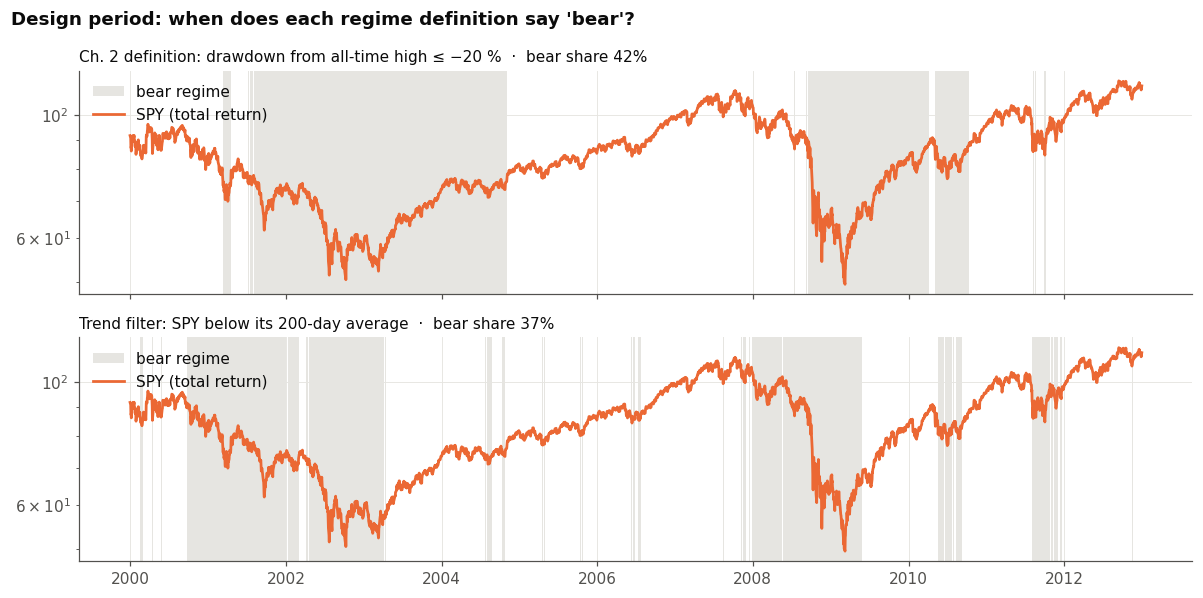

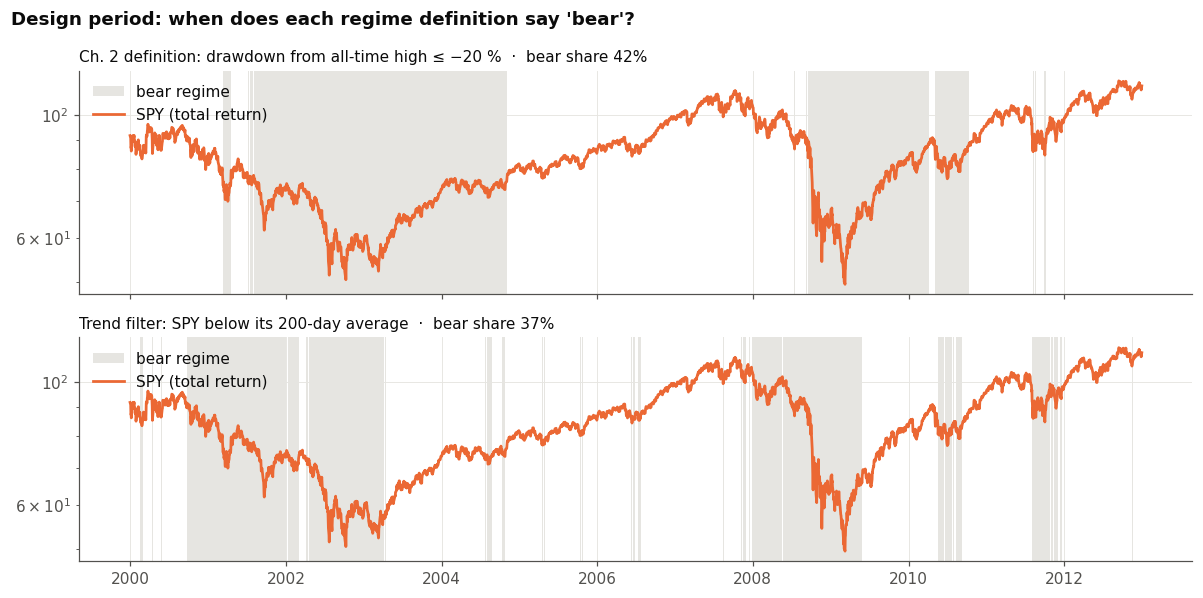

In [2]:
reg_ath = make_regime(spy, "drawdown_ath")
reg_trend = make_regime(spy, "trend_200d")
s, e = PERIODS["design"]
save(ch6plots.plot_regime_definitions, "regime_definitions.png", spy=spy, start=s, end=e, regimes={
    "Ch. 2 definition: drawdown from all-time high ≤ −20 %": reg_ath,
    "Trend filter: SPY below its 200-day average": reg_trend,
})

## Part 2: Design-period choices (the only place we look at performance to decide)

Six pre-declared variants: 3 regime definitions (Ch. 2 all-time-high drawdown, drawdown from the 1-year high, 200-day trend) × with/without a 12-1 momentum sleeve (top 4 sectors). All use vol targeting. Decision rule: highest Sharpe, and if the difference is small prefer the simpler, lower-turnover rule.

In [3]:
variants = {}
for method in ["drawdown_ath", "drawdown_1y", "trend_200d"]:
    for mom in [True, False]:
        variants[f"{method} | momentum={mom}"] = StrategyConfig(regime_method=method, use_momentum=mom)

s, e = PERIODS["design"]
runs = {k: backtest(sectors, spy, rf, cfg, s, e) for k, cfg in variants.items()}
design_tbl = metrics_table({k: r.returns for k, r in runs.items()}, rf, spy_r, runs)
design_tbl[["CAGR", "Volatility", "Sharpe", "Max drawdown", "Calmar", "Turnover / yr"]].sort_values("Sharpe", ascending=False)

,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Turnover / yr
trend_200d | momentum=False,0.043,0.124,0.232,-0.315,0.136,1.867
drawdown_ath | momentum=False,0.038,0.122,0.195,-0.329,0.115,2.087
trend_200d | momentum=True,0.038,0.128,0.195,-0.303,0.126,4.149
drawdown_1y | momentum=False,0.038,0.125,0.194,-0.315,0.120,2.050
drawdown_1y | momentum=True,0.029,0.128,0.126,-0.311,0.094,4.409
drawdown_ath | momentum=True,0.028,0.125,0.119,-0.329,0.086,3.308


**Decision.** The trend filter beats both drawdown definitions whichever selection rule is used, so it is adopted. Without the momentum sleeve the Sharpe is slightly *higher* (0.23 vs 0.20) with less than half the turnover, so momentum is dropped. Sector momentum is known to have struggled in the 2000s (and crashed in 2009), which fits.

> Caveat for interviews: 6 variants were compared, so the design-period Sharpe of the winner is optimistically biased (selection / multiple testing). That is exactly why validation and holdout are reported separately and nothing is changed after looking at them.

## Part 3: Out-of-sample results of the final strategy

In [4]:
FULL = ("1999-12-31", None)
all_periods = {**PERIODS, "full": FULL}

def run_period(s, e):
    res = {k: backtest(sectors, spy, rf, cfg, s, e) for k, cfg in ABLATIONS.items()}
    ser = {k: r.returns for k, r in res.items()}
    ser["SPY"] = spy_r.loc[s:e].fillna(0.0)
    return ser, res

period_tables, period_series = {}, {}
for name, (s, e) in all_periods.items():
    ser, res = run_period(s, e)
    period_series[name] = (ser, res)
    period_tables[name] = metrics_table(ser, rf, spy_r, res)

cols = ["CAGR", "Volatility", "Sharpe", "Sortino", "Max drawdown", "Calmar", "Beta vs SPY", "Turnover / yr", "Avg exposure"]
summary = pd.concat({p: t.loc[["+ vol target (final)", "EW sectors", "SPY"], cols] for p, t in period_tables.items()})
summary.to_csv(FIG_DIR / "summary_by_period.csv")
summary

CAGR  Volatility  Sharpe  Sortino  Max drawdown  Calmar  Beta vs SPY  Turnover / yr  Avg exposure
design     + vol target (final) 0.043       0.124   0.232    0.321        -0.315   0.136        0.456          1.867         0.828
           EW sectors           0.046       0.202   0.221    0.310        -0.533   0.086        0.900          0.407         1.000
           SPY                  0.016       0.216   0.085    0.121        -0.552   0.029        1.000            NaN           NaN
validation + vol target (final) 0.076       0.136   0.553    0.747        -0.297   0.257        0.789          2.844         0.942
           EW sectors           0.077       0.158   0.502    0.675        -0.362   0.214        0.962          0.434         0.999
           SPY                  0.100       0.162   0.623    0.845        -0.337   0.297        1.000            NaN           NaN
holdout    + vol target (final) 0.121       0.110   0.824    1.162        -0.113   1.069        0.515          3.115         0.860
           EW sectors           0.184       0.155   0.976    1.425        -0.193   0.953        0.833          0.495         0.999
           SPY                  0.202       0.173   0.978    1.424        -0.245   0.824        1.000            NaN           NaN
full       + vol target (final) 0.072       0.124   0.464    0.640        -0.315   0.228        0.532          2.395         0.867
           EW sectors           0.088       0.180   0.453    0.634        -0.533   0.166        0.900          0.362         1.000
           SPY                  0.082       0.192   0.405    0.571        -0.552   0.148        1.000            NaN           NaN

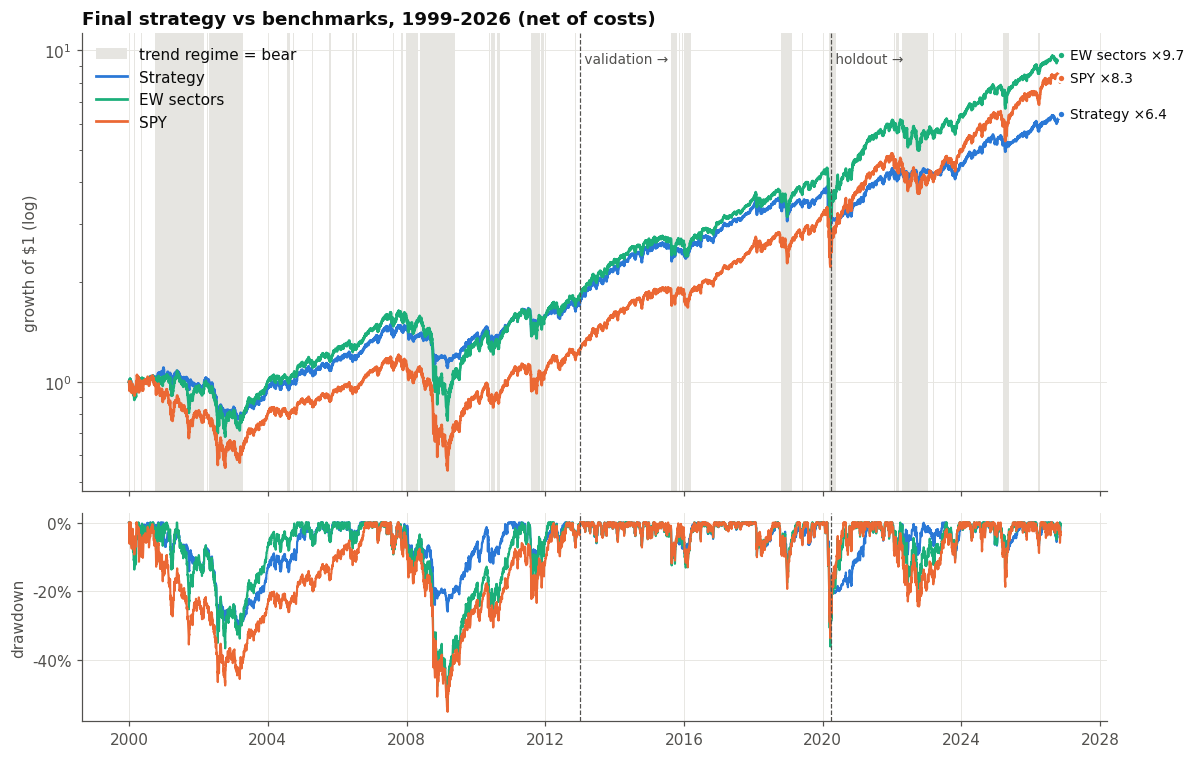

In [5]:
ser, res = period_series["full"]
final = res["+ vol target (final)"]
save(ch6plots.plot_equity_drawdown, "equity_drawdown.png", regime=final.regime,
     series={"Strategy": (ser["+ vol target (final)"], "strategy"), "EW sectors": (ser["EW sectors"], "ew"),
             "SPY": (ser["SPY"], "spy")},
     boundaries={p: PERIODS[p][0] for p in ["validation", "holdout"]})

### Is the timing worth anything? A volatility-matched benchmark

Lower volatility is easy to get: just hold less stock. The fair comparison is a **static SPY + T-bill mix with the same average volatility** as the strategy. If the strategy does not beat that, its rules add nothing beyond de-risking.

In [6]:
rows = {}
for name, (s, e) in all_periods.items():
    ser, res = period_series[name]
    strat = ser["+ vol target (final)"]
    a = strat.std() / ser["SPY"].std()                      # equity share that matches volatility
    rf_p = rf.reindex(strat.index).fillna(0.0)
    static = a * ser["SPY"] + (1 - a) * rf_p
    t = metrics_table({"strategy": strat, f"static {a:.0%} SPY": static}, rf, spy_r)
    rows[name] = t[["CAGR", "Volatility", "Sharpe", "Max drawdown", "Calmar"]].set_axis(["strategy", "vol-matched SPY"])
vol_matched = pd.concat(rows)
vol_matched

CAGR  Volatility  Sharpe  Max drawdown  Calmar
design     strategy        0.043       0.124   0.232        -0.315   0.136
           vol-matched SPY 0.024       0.124   0.085        -0.348   0.069
validation strategy        0.076       0.136   0.553        -0.297   0.257
           vol-matched SPY 0.087       0.136   0.623        -0.289   0.300
holdout    strategy        0.121       0.110   0.824        -0.113   1.069
           vol-matched SPY 0.140       0.110   0.978        -0.156   0.898
full       strategy        0.072       0.124   0.464        -0.315   0.228
           vol-matched SPY 0.064       0.124   0.405        -0.386   0.166

### Ablation: what each idea adds (full period and holdout)

In [7]:
pd.concat({p: period_tables[p][["CAGR", "Volatility", "Sharpe", "Max drawdown", "Calmar", "Turnover / yr"]]
           for p in ["design", "validation", "holdout", "full"]})

CAGR  Volatility  Sharpe  Max drawdown  Calmar  Turnover / yr
design     EW sectors            0.046       0.202   0.221        -0.533   0.086          0.407
           + inverse-vol         0.045       0.186   0.220        -0.498   0.091          0.839
           + trend regime switch 0.043       0.164   0.212        -0.397   0.108          1.979
           + vol target (final)  0.043       0.124   0.232        -0.315   0.136          1.867
           SPY                   0.016       0.216   0.085        -0.552   0.029            NaN
validation EW sectors            0.077       0.158   0.502        -0.362   0.214          0.434
           + inverse-vol         0.081       0.155   0.529        -0.351   0.230          0.873
           + trend regime switch 0.083       0.152   0.554        -0.335   0.249          2.929
           + vol target (final)  0.076       0.136   0.553        -0.297   0.257          2.844
           SPY                   0.100       0.162   0.623        -0.337   0.297            NaN
holdout    EW sectors            0.184       0.155   0.976        -0.193   0.953          0.495
           + inverse-vol         0.171       0.149   0.935        -0.187   0.911          0.895
           + trend regime switch 0.150       0.138   0.866        -0.136   1.097          3.700
           + vol target (final)  0.121       0.110   0.824        -0.113   1.069          3.115
           SPY                   0.202       0.173   0.978        -0.245   0.824            NaN
full       EW sectors            0.088       0.180   0.453        -0.533   0.166          0.362
           + inverse-vol         0.086       0.170   0.457        -0.498   0.173          0.789
           + trend regime switch 0.081       0.155   0.455        -0.397   0.204          2.586
           + vol target (final)  0.072       0.124   0.464        -0.315   0.228          2.395
           SPY                   0.082       0.192   0.405        -0.552   0.148            NaN

### Behaviour by Chapter 2 regime (annualised mean return on regime days)

In [8]:
ser, _ = period_series["full"]
regime_breakdown({k: ser[k] for k in ["+ vol target (final)", "EW sectors", "SPY"]}, reg_ath)

,bull,neutral,bear
+ vol target (final),0.217,-0.036,-0.061
EW sectors,0.263,-0.023,-0.087
SPY,0.301,-0.073,-0.103
share of days,0.476,0.312,0.211


In [9]:
# What does it hold? Monthly average weight per sector
w = final.weights.resample("ME").mean().T
w.index = [ETF_TO_SECTOR[t] for t in w.index]
save(ch6plots.plot_weights, "weights_heatmap.png", monthly_weights=w)
print("Share of months each sector is in the defensive (bear) sleeve:")
bear_months = final.regime.resample("ME").last() == "bear"
(w.loc[:, bear_months.reindex(w.columns).fillna(False).values] > 0.05).mean(axis=1).sort_values(ascending=False)

Share of months each sector is in the defensive (bear) sleeve:


Consumer Defensive       0.975
Utilities                0.963
Healthcare               0.600
Energy                   0.537
Basic Materials          0.250
Consumer Cyclical        0.212
Industrials              0.212
Financial Services       0.188
Technology               0.175
Real Estate              0.138
Communication Services   0.075
dtype: float64

## Part 4: Robustness

1. **Statistical significance:** stationary block bootstrap (mean block 21 days) of the Sharpe difference. Daily returns are autocorrelated and volatility clusters, so i.i.d. resampling would understate the uncertainty (the same issue flagged for the Ch. 2 Kruskal-Wallis test).
2. **Parameter sensitivity** on the design period: if performance only works for one exact setting, it is overfit.
3. **Transaction costs:** how much cost the strategy can absorb.

In [10]:
boot = {}
for p in ["validation", "holdout", "full"]:
    ser, _ = period_series[p]
    for bench in ["SPY", "EW sectors"]:
        boot[(p, f"vs {bench}")] = stationary_bootstrap_sharpe_diff(ser["+ vol target (final)"], ser[bench], rf, n_boot=2000)
pd.DataFrame(boot).T

sharpe_diff  ci90_low  ci90_high  p_value_diff_le_0
validation vs SPY              -0.070    -0.241      0.091              0.748
           vs EW sectors        0.051    -0.121      0.177              0.296
holdout    vs SPY              -0.154    -0.536      0.205              0.749
           vs EW sectors       -0.153    -0.419      0.112              0.820
full       vs SPY               0.059    -0.101      0.224              0.272
           vs EW sectors        0.011    -0.127      0.154              0.458

**Reading the robustness checks.**
- No Sharpe difference is significant: every 90 % bootstrap interval contains 0. The strategy is a **risk** improvement, not a proven return improvement.
- All 60 parameter settings beat SPY's design-period Sharpe (0.09) by a wide margin, so the result does not hinge on one lucky setting. 4-5 defensive sectors would have scored slightly better than the pre-declared 3. We keep 3 on purpose: picking the best cell would be tuning on the grid.
- The strategy trades about 2.4× its NAV per year, so costs matter but do not destroy it. At 50 bps (5× a realistic ETF cost) the Sharpe is still close to SPY's.

In [11]:
s, e = PERIODS["design"]
grid = parameter_grid(sectors, spy, rf, {"vol_target": [0.08, 0.10, 0.12, 0.15, 0.20],
                                         "defensive_k": [2, 3, 4, 5],
                                         "vol_window": [42, 63, 126]}, s, e)
print(f"{len(grid)} settings · Sharpe range {grid.Sharpe.min():.2f}–{grid.Sharpe.max():.2f} · median {grid.Sharpe.median():.2f}")
print(f"Max drawdown range {grid['Max drawdown'].min():.0%} to {grid['Max drawdown'].max():.0%} (SPY: −55 %)")
heat = grid[grid.vol_window == 63].pivot(index="defensive_k", columns="vol_target", values="Sharpe")
spy_design_sharpe = period_tables["design"].loc["SPY", "Sharpe"]
save(ch6plots.plot_sensitivity, "sensitivity_heatmap.png", heat=heat, spy_sharpe=spy_design_sharpe)
heat

60 settings · Sharpe range 0.16–0.28 · median 0.24
Max drawdown range -40% to -19% (SPY: −55 %)


vol_target,0.080,0.100,0.120,0.150,0.200
defensive_k,,,,,
2,0.222,0.224,0.218,0.200,0.200
3,0.234,0.236,0.232,0.219,0.234
4,0.263,0.266,0.262,0.247,0.261
5,0.261,0.263,0.259,0.258,0.276


In [12]:
from dataclasses import replace
cost_rows = {}
for bps in [0, 5, 10, 25, 50]:
    r = backtest(sectors, spy, rf, replace(FINAL, cost_bps=bps), *FULL)
    cost_rows[f"{bps} bps"] = r.returns
metrics_table(cost_rows, rf, spy_r)[["CAGR", "Sharpe", "Max drawdown"]]

,CAGR,Sharpe,Max drawdown
0 bps,0.074,0.483,-0.312
5 bps,0.073,0.474,-0.313
10 bps,0.072,0.464,-0.315
25 bps,0.068,0.435,-0.319
50 bps,0.062,0.387,-0.326


## Part 5: The corrected Strategy Builder (profiling tool)

The website's Strategy Builder (`website/content/strategy_stats.json`) had three bugs:

1. **Volume-weighted *price* index** Σ(P·V)/ΣV. A $500 stock joining a basket of $20 stocks looks like a +2 400 % "return". Median basket volatility in the JSON: **508 %** for "all", **276 %** for "top5", versus 22 % for ETFs.
2. **All 396 regime rows are empty** (n_days = 0). The regime dropdown on the website never showed real numbers.
3. **NaN → "gambler"**: `NaN < threshold` is False, so empty rows fell into the high/high bucket. That is why 412 of 528 rows are "gambler".

`src/strategy/profiles.py` fixes all three: compounding of lagged weighted returns, regime statistics from regime days (annualised mean log return, since regime days are not contiguous), tertiles **within each regime**, and NaN → "insufficient data". Below it is applied to the sector ETFs (stock-level rows need the full Kaggle stock dataset; see README).

In [13]:
import json
old = pd.DataFrame(json.load(open("website/content/strategy_stats.json")))
print("Old JSON — profile counts:", old.profile.value_counts().to_dict())
print("Old JSON — regime rows with data:", int((old.query("regime != 'all'").n_days > 0).sum()), "of", int((old.regime != "all").sum()))

end = PERIODS["validation"][1]  # same window as the project dataset
rows = []
for etf in sectors.columns:
    r = sectors[etf].loc[:end].pct_change(fill_method=None).dropna()
    st = profiles.regime_stats(r, reg_ath, rf)
    st.insert(0, "sector", ETF_TO_SECTOR[etf]); st.insert(1, "type", "etf")
    rows.append(st)
new = pd.concat(rows, ignore_index=True)
new["profile"] = profiles.classify_profiles(new)
new.pivot(index="sector", columns="regime", values="profile")[["all", "bull", "neutral", "bear"]]

Old JSON — profile counts: {'gambler': 412, 'steady': 32, 'champion': 28, 'disaster': 21, 'dormant': 12, 'fragile': 10, 'adventurous': 7, 'balanced': 6}
Old JSON — regime rows with data: 0 of 396


regime,all,bull,neutral,bear
sector,,,,
Basic Materials,balanced,adventurous,champion,champion
Communication Services,disaster,balanced,disaster,insufficient data
Consumer Cyclical,champion,champion,balanced,champion
Consumer Defensive,steady,dormant,genius,steady
Energy,disaster,disaster,gambler,disaster
Financial Services,disaster,adventurous,disaster,disaster
Healthcare,genius,genius,steady,genius
Industrials,champion,genius,steady,balanced
Real Estate,dormant,dormant,fragile,insufficient data


In [14]:
new.pivot(index="sector", columns="regime", values="ann_return")[["all", "bull", "neutral", "bear"]].style.format("{:.1%}")

regime,all,bull,neutral,bear
sector,,,,
Basic Materials,5.8%,22.1%,-5.6%,-4.6%
Communication Services,-7.8%,23.3%,-54.6%,nan%
Consumer Cyclical,7.6%,27.9%,-7.2%,-3.9%
Consumer Defensive,5.7%,15.6%,2.3%,-5.4%
Energy,3.1%,14.6%,0.8%,-11.4%
Financial Services,2.1%,27.4%,-10.6%,-17.5%
Healthcare,7.5%,29.9%,-9.0%,-4.9%
Industrials,6.2%,29.9%,-8.0%,-10.3%
Real Estate,2.8%,16.4%,-25.0%,nan%


## Conclusions

- **What it is:** a defensive, risk-managed sector allocation. It holds all sectors (inverse-vol) in up-trends, rotates into the 3 lowest-beta sectors when SPY breaks its 200-day average, and scales exposure to 12 % volatility.
- **What it achieves (1999-2026, net of costs):** about **half the max drawdown of SPY** (−31 % vs −55 %), about two-thirds of the volatility, beta ≈ 0.5, a slightly higher Sharpe (0.46 vs 0.41) and a clearly higher Calmar ratio (0.23 vs 0.15). The drawdown reduction also holds in the never-seen holdout (−11 % vs −25 %).
- **Against a fair benchmark** (static SPY + T-bills at the same volatility) it wins over the full period (Sharpe 0.46 vs 0.41, max DD −31 % vs −39 %). That edge comes from the long 2000-2012 bear markets, though. In 2013-2026 the static mix had the higher Sharpe, and the strategy only kept a smaller drawdown (holdout −11 % vs −16 %).
- **What it does not achieve:** it does **not** beat SPY on return, and no Sharpe difference is **statistically significant** (bootstrap 90 % CIs include 0). In the 2013-2026 bull market, which was dominated by mega-cap tech, a cap-weighted SPY was very hard to beat.
- **It rediscovers Chapter 2 without being told.** The defensive sleeve is chosen purely by trailing beta, yet it ends up holding Consumer Defensive (~97 % of bear months), Utilities (~96 %) and Healthcare (~60 %): the same sectors Ch. 2 found to be most resilient in Bear/Neutral markets.
- **What the ablation teaches:** each layer mainly buys *drawdown protection*. Momentum (a classic idea) did not survive on the design data and was dropped. The Ch. 2 regime definition is descriptive, not predictive, because it lags by years.
- **Limitations:** a single market (US) and asset class; ETF list and sector definitions known *ex post*; 6 design variants compared (selection bias); no taxes; T-bill cash; the trend filter can whipsaw in sideways markets (2011, 2015-16, 2018).
- **Next steps:** add a bond/gold sleeve for the bear regime instead of low-beta equities, use the Ch. 5 top-5 baskets as an alternative implementation, and do walk-forward re-estimation of the vol target.